# **Problem Statement**

## **Business Context**

Workplace safety in hazardous environments like construction sites and industrial plants is crucial to prevent accidents and injuries. One of the most important safety measures is ensuring workers wear safety helmets, which protect against head injuries from falling objects and machinery. Non-compliance with helmet regulations increases the risk of serious injuries or fatalities, making effective monitoring essential, especially in large-scale operations where manual oversight is prone to errors and inefficiency.

To overcome these challenges, SafeGuard Corp plans to develop an automated image analysis system to detect whether workers are wearing safety helmets. This system will improve safety enforcement, ensuring compliance and reducing the risk of head injuries. By automating helmet monitoring, SafeGuard aims to enhance efficiency, scalability, and accuracy, ultimately fostering a safer work environment while minimizing human error in safety oversight.

## **Objective**

As a data scientist at SafeGuard Corp, you are tasked with developing an image classification model that classifies images into one of two categories:
- **With Helmet:** Workers wearing safety helmets.
- **Without Helmet:** Workers not wearing safety helmets.

The ultimate objective is to prepare the model for deployment as part of an automated monitoring system. This system will enable real-time analysis of images and assist in ensuring compliance with workplace safety regulations.

## **Data Dictionary**

The dataset consists of **4125 images**, equally divided into two categories:

- **With Helmet:** 3161 images showing workers wearing helmets.
- **Without Helmet:** 964 images showing workers not wearing helmets.

**Dataset Characteristics:**
- **Variations in Conditions:** Images include diverse environments such as construction sites, factories, and industrial settings, with variations in lighting, angles, and worker postures to simulate real-world conditions.
- **Worker Activities:** Workers are depicted in actions such as standing, using tools, or moving, ensuring robust model learning for various scenarios.

# **Installing and Importing the Necessary Libraries**

In [1]:
!pip install tensorflow[and-cuda] scikit-learn==1.6.1 opencv-python==4.12.0.88 seaborn==0.13.2 matplotlib==3.10.0 numpy==2.0.2 pandas==2.2.2 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 28.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 83.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.3/363.3 MB 5.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 73.7 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.9/24.9 MB 51.5 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 895.7/895.7 kB 45.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 577.2/577.2 MB 2.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.5/192.5 MB 7.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 30.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.3/130.3 MB 13.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.6/217.6 MB 2.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [2]:
import os
import random
import numpy as np                                                                               # Importing numpy for Matrix Operations
import pandas as pd
import seaborn as sns
import matplotlib.image as mpimg                                                                              # Importing pandas to read CSV files
import matplotlib.pyplot as plt                                                                  # Importting matplotlib for Plotting and visualizing images
import math                                                                                      # Importing math module to perform mathematical operations
import cv2


# Tensorflow modules
import keras
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator                              # Importing the ImageDataGenerator for data augmentation
from tensorflow.keras.models import Sequential                                                   # Importing the sequential module to define a sequential model
from tensorflow.keras.layers import Dense,Dropout,Flatten,Conv2D,MaxPooling2D,BatchNormalization # Defining all the layers to build our CNN Model
from tensorflow.keras.optimizers import Adam,SGD                                                 # Importing the optimizers which can be used in our model
from sklearn import preprocessing                                                                # Importing the preprocessing module to preprocess the data
from sklearn.model_selection import train_test_split                                             # Importing train_test_split function to split the data into train and test
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import Model
from keras.applications.vgg16 import VGG16                                               # Importing confusion_matrix to plot the confusion matrix

# Display images using OpenCV
from google.colab.patches import cv2_imshow

#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report
from sklearn.metrics import mean_squared_error as mse                                                 # Importing cv2_imshow from google.patches to display images

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

2026-04-10 21:05:25.663705: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775855126.075987      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775855126.208181      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775855127.262391      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775855127.262435      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775855127.262438      55 computation_placer.cc:177] computation placer alr

In [3]:
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
print(tf.__version__)

Num GPUs Available: 2
2.19.0


In [5]:
# 1. Set Python random seed
random.seed(812)

# 2. Set NumPy random seed
np.random.seed(812)

# 3. Set TensorFlow seed (covers Keras + backend)
tf.keras.utils.set_random_seed(812)

# 4. Enable deterministic GPU ops (if using GPU)
tf.config.experimental.enable_op_determinism()

# **Data Overview**


##Loading the data

In [16]:
import os;
os.listdir('/kaggle/input/')
import pandas as pd

labels_df = pd.read_csv('/kaggle/input/datasets/preetinancykujur/data-helmnet/labels.csv')
print("Dataset loaded: labels.csv -> labels_df")
print("Shape (rows, columns):", labels_df.shape)
print("\nFirst rows:")
print(labels_df.head())
print("\nClass distribution (0 = Without Helmet, 1 = With Helmet):")
print(labels_df["label"].value_counts().sort_index())

Dataset loaded: labels.csv -> labels_df
Shape (rows, columns): (4125, 1)

First rows:
   label
0      0
1      0
2      0
3      0
4      0

Class distribution (0 = Without Helmet, 1 = With Helmet):
label
0     964
1    3161
Name: count, dtype: int64


# **Exploratory Data Analysis**

In this section we:
- Plot random images from each class and print their corresponding labels
- Check for class imbalance
- Summarize key meaningful observations from EDA


### Plot random images from each class and print their corresponding labels

Below we sample rows stratified by class (label **0** = Without Helmet, **1** = With Helmet). If an `Images/` folder is present, we display the images; otherwise we print the sampled row indices and labels.


Index 614 -> label=0 (Without Helmet)
Index 723 -> label=0 (Without Helmet)
Index 559 -> label=0 (Without Helmet)
Index 3270 -> label=1 (With Helmet)
Index 3027 -> label=1 (With Helmet)
Index 4101 -> label=1 (With Helmet)


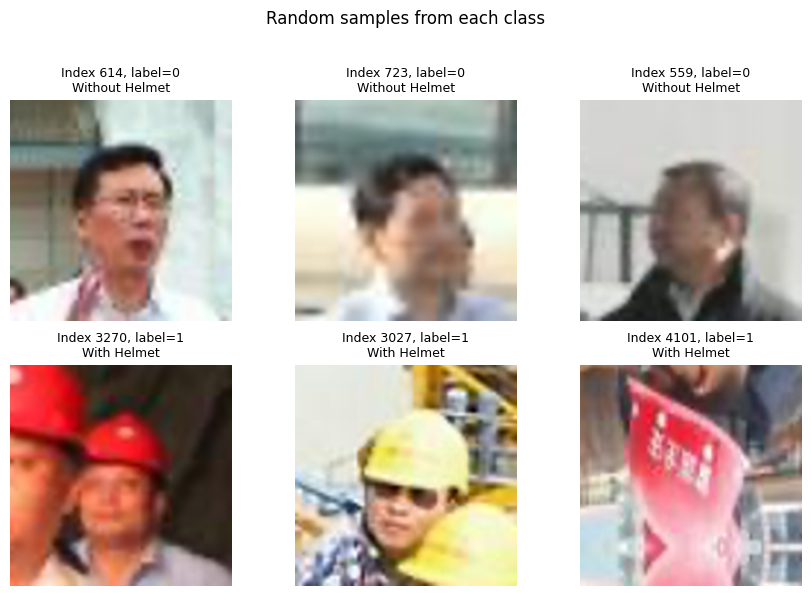

In [22]:
# Kaggle dataset path (change if you copy files elsewhere)
IMAGES_NPY_PATH = "/kaggle/input/datasets/preetinancykujur/data-helmnet/images.npy"

LABEL_NAMES = {0: "Without Helmet", 1: "With Helmet"}


def prepare_for_imshow(img):
    """Convert one image to float RGB in [0, 1] for matplotlib."""
    x = np.asarray(img)
    if x.ndim == 2:
        x = np.stack([x, x, x], axis=-1)
    elif x.shape[-1] == 1:
        x = np.concatenate([x, x, x], axis=-1)
    x = x.astype(np.float32)
    if x.max() > 1.0:
        x = x / 255.0
    return np.clip(x, 0.0, 1.0)


labels_aligned = labels_df.reset_index(drop=True)
images_stack = np.load(IMAGES_NPY_PATH)

if images_stack.shape[0] != len(labels_aligned):
    raise ValueError(
        f"images.npy has {images_stack.shape[0]} rows but labels_df has {len(labels_aligned)} rows; "
        "they must align index-by-index."
    )

rng = np.random.default_rng(812)
n_per_class = int(min(3, labels_aligned["label"].value_counts().min()))
fig, axes = plt.subplots(2, n_per_class, figsize=(n_per_class * 2.9, 5.8))

for r, lab in enumerate((0, 1)):
    pool = labels_aligned.index[labels_aligned["label"] == lab].to_numpy()
    picks = rng.choice(pool, size=n_per_class, replace=False)
    for c in range(n_per_class):
        ax = axes[r] if n_per_class == 1 else axes[r, c]
        idx = int(picks[c])
        disp = prepare_for_imshow(images_stack[idx])
        ax.imshow(disp)
        li = int(labels_aligned.loc[idx, "label"])
        ax.set_title(
            f"Index {idx}, label={li}\n{LABEL_NAMES[lab]}",
            fontsize=9,
        )
        ax.axis("off")
        print(f"Index {idx} -> label={li} ({LABEL_NAMES[lab]})")

plt.suptitle("Random samples from each class", y=1.02)
plt.tight_layout()
plt.show()


### Check for class imbalance

We quantify counts/percentages per class and visualize the skew. Severe imbalance motivates stratified splits and class weights in training.


Class counts and percentages:
                    count  percent
Without Helmet (0)    964    23.37
With Helmet (1)      3161    76.63

Imbalance ratio (majority / minority): 3.279045643153527


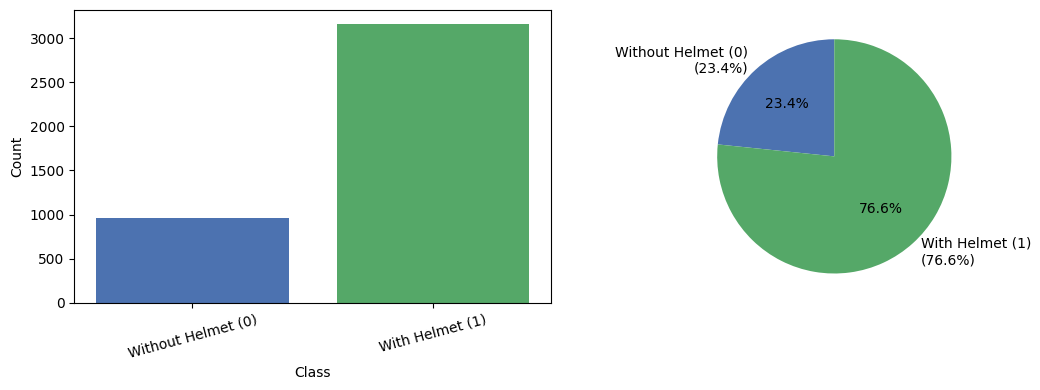

In [23]:
counts = labels_df["label"].value_counts().sort_index()
counts = counts.reindex([0, 1]).fillna(0).astype(int)

pct_series = (counts / counts.sum() * 100).round(2)
summary = pd.DataFrame({"count": counts, "percent": pct_series})
summary.index = ["Without Helmet (0)", "With Helmet (1)"]

print("Class counts and percentages:")
print(summary)
print("\nImbalance ratio (majority / minority):", counts.max() / counts.min())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(summary.index, counts.values, color=["#4c72b0", "#55a868"])
axes[0].set_ylabel("Count")
axes[0].set_xlabel("Class")
axes[0].tick_params(axis="x", rotation=15)

pie_labels = [
    f"{name}\n({p:.1f}%)"
    for name, p in zip(summary.index, pct_series.values)
]
axes[1].pie(
    counts.values,
    labels=pie_labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4c72b0", "#55a868"],
)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


### Key meaningful observations from EDA

- **Class imbalance:** *With Helmet* (label 1) is the majority class (~77% vs ~23%). A model may favor predicting helmet present; use **stratified** splits and consider **class weights**, resampling, or strong per-class metrics (precision/recall, F1, confusion matrix).
- **Labels vs images:** Each row in `labels.csv` should match one image file in sorted filename order under `Images/` (or `images/`, `data/Images/`, `Dataset/Images/`). Mismatched counts or order will break training.
- **Visual diversity:** The data dictionary notes varied sites, lighting, angles, and activities—helpful for generalization but harder than a single controlled setting. Random samples should reflect that once images are available.
- **Scale:** 4125 labeled images is enough for a modest CNN or transfer learning; watch validation metrics on the minority *Without Helmet* class in particular.


# **Data Pre-processing**

We will:
- Split the data into **train**, **validation**, and **test** sets (stratified by class)
- Apply **normalization** (pixel values scaled to the [0, 1] range) and compute **class weights** to mitigate imbalance during training


### Split the data into train, validation, and test

We use **stratified** `train_test_split` so each split preserves the class ratio (~77% / ~23%).


In [28]:
from sklearn.model_selection import train_test_split

IMG_SIZE = (224, 224)

KAGGLE_HELMNET_ROOT = Path("/kaggle/input/datasets/preetinancykujur/data-helmnet")
IMAGES_NPY_PATH  = KAGGLE_HELMNET_ROOT / "images.npy"
LABELS_CSV_PATH  = KAGGLE_HELMNET_ROOT / "labels.csv"

labels_df    = pd.read_csv(LABELS_CSV_PATH)
images_stack = np.load(IMAGES_NPY_PATH)

if images_stack.shape[0] != len(labels_df):
    raise ValueError(
        f"images.npy has {images_stack.shape[0]} samples "
        f"but labels.csv has {len(labels_df)} rows."
    )

x = np.asarray(images_stack, dtype=np.float32)

if x.ndim == 3:                      # (N, H, W) → add channel dim
    x = np.expand_dims(x, axis=-1)
if x.shape[-1] == 1:                 # grayscale → RGB
    x = np.repeat(x, 3, axis=-1)
elif x.shape[-1] != 3:
    raise ValueError(f"Expected 1 or 3 channels; got shape {x.shape}")

if x.max() <= 1.0:                   # [0,1] → [0,255]
    x = x * 255.0
x = np.clip(np.round(x), 0, 255).astype(np.uint8)   # pure numpy, no TF/GPU

# cv2.resize expects (W, H) not (H, W)
X = np.stack(
    [cv2.resize(img, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_LINEAR)
     for img in x],
    axis=0
)

y = labels_df["label"].to_numpy().astype(np.float32)

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=812
)
val_ratio = 0.2 / 0.8
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio, stratify=y_temp, random_state=812
)

print("Train     :", X_train.shape, y_train.shape)
print("Validation:", X_val.shape,   y_val.shape)
print("Test      :", X_test.shape,  y_test.shape)

Train     : (2475, 224, 224, 3) (2475,)
Validation: (825, 224, 224, 3) (825,)
Test      : (825, 224, 224, 3) (825,)


### Apply normalization (and class weights)

Pixels are scaled to **[0, 1]** for stable training. **Balanced class weights** are computed from `y_train` to reduce bias toward the majority class.


In [29]:
# Scale pixel values to [0, 1] for training (CNN from scratch and generic pipelines)
X_train = X_train.astype(np.float32) / 255.0
X_val = X_val.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Train pixel range:", float(X_train.min()), float(X_train.max()))
print("Validation pixel range:", float(X_val.min()), float(X_val.max()))
print("Test pixel range:", float(X_test.min()), float(X_test.max()))

from sklearn.utils.class_weight import compute_class_weight

_classes = np.unique(y_train.astype(int))
_cw = compute_class_weight("balanced", classes=_classes, y=y_train.astype(int))
class_weight = {int(c): float(w) for c, w in zip(_classes, _cw)}
print("Class weights (for imbalanced data):", class_weight)


Train pixel range: 0.0 1.0
Validation pixel range: 0.0 1.0
Test pixel range: 0.0 1.0
Class weights (for imbalanced data): {0: 2.1410034602076125, 1: 0.6523458091723774}


# **Model Building**

We build and compare: (1) CNN from scratch, (2) VGG-16 frozen base, (3) VGG-16 + FFNN, (4) VGG-16 + FFNN + data augmentation—then select the best model by validation performance.


##Model Evaluation Criterion

## Utility Functions

In [30]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)


    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='micro')  # to compute Recall
    precision = precision_score(target, pred, average='micro')  # to compute Precision
    f1 = f1_score(target, pred, average='micro')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame({"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},index=[0],)

    return df_perf

In [31]:
def plot_confusion_matrix(model,predictors,target,ml=False):
    """
    Function to plot the confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    ml: To specify if the model used is an sklearn ML model or not (True means ML model)
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)

    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(target,pred)
    f, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        confusion_matrix,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax
    )
    plt.show()

In [32]:
def show_prediction_grid(model, images, labels_true, title, n_samples=6, threshold=0.5):
    """Show validation images with true label and predicted probability of class 1 (With Helmet)."""
    rng = np.random.default_rng(812)
    n_samples = min(n_samples, len(images))
    idx = rng.choice(len(images), size=n_samples, replace=False)
    preds = model.predict(images[idx], verbose=0).reshape(-1)

    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    axes = axes.ravel()
    for ax, i, p in zip(axes, idx, preds):
        ax.imshow(np.clip(images[i], 0, 1))
        pred_cls = int(p >= threshold)
        ax.set_title(
            f"True: {int(labels_true[i])} | P(helmet): {p:.2f} | Pred: {pred_cls}",
            fontsize=8,
        )
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


## Convolutional Neural Network (CNN) from Scratch

We will:
- Define the model architecture
- Define the configuration (loss function, optimizer, epochs, batch size)
- Train the model
- Check and comment on the performance of the model
- Visualize sample predictions on the validation set


### 1. Define the model

Stacked convolutional blocks with batch normalization, max pooling, and a dense classifier head. Output is a single sigmoid unit for binary classification.


In [33]:
model_scratch = Sequential(
    [
        Conv2D(32, (3, 3), activation="relu", padding="same", input_shape=(224, 224, 3)),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ]
)
model_scratch.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,457 (49.36 MB)

 Trainable params: 12,939,009 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

### 2. Configuration: loss function, optimizer, epochs, batch size

| Setting | Choice |
|--------|--------|
| Loss | `binary_crossentropy` (binary labels) |
| Optimizer | `Adam` with learning rate `1e-4` |
| Epochs | `15` (with early stopping on `val_loss`) |
| Batch size | `32` |
| Extra | `class_weight` from EDA/preprocessing for imbalance; early stopping `patience=3` |


In [35]:
EPOCHS_SCRATCH = 15
BATCH_SIZE_SCRATCH = 32

model_scratch.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

callbacks_scratch = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
]


### 3. Train the model


In [36]:
history_scratch = model_scratch.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_SCRATCH,
    batch_size=BATCH_SIZE_SCRATCH,
    class_weight=class_weight,
    callbacks=callbacks_scratch,
    verbose=1,
)


Epoch 1/15


2026-04-10 21:35:01.549362: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}
I0000 00:00:1775856904.551647     262 cuda_dnn.cc:529] Loaded cuDNN version 90300


78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.7562 - loss: 1.0997

2026-04-10 21:35:18.648173: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


78/78 ━━━━━━━━━━━━━━━━━━━━ 20s 162ms/step - accuracy: 0.7571 - loss: 1.0960 - val_accuracy: 0.2339 - val_loss: 6.9496
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 143ms/step - accuracy: 0.8828 - loss: 0.3183 - val_accuracy: 0.2339 - val_loss: 8.4945
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.9327 - loss: 0.1909 - val_accuracy: 0.2461 - val_loss: 8.3000
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 144ms/step - accuracy: 0.9432 - loss: 0.1539 - val_accuracy: 0.4521 - val_loss: 4.5759
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.9458 - loss: 0.1447 - val_accuracy: 0.6836 - val_loss: 2.0606
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 138ms/step - accuracy: 0.9563 - loss: 0.1151 - val_accuracy: 0.8412 - val_loss: 0.7032
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 141ms/step - accuracy: 0.9606 - loss: 0.1031 - val_accuracy: 0.8606 - val_loss: 0.4745
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 140ms/step - accuracy: 0.9650 - loss: 0.0715 - val_accuracy: 0.898

### 4. Check and comment on the performance

We report validation **loss/accuracy**, a **classification report** (per-class precision/recall/F1), and the **confusion matrix**. With class imbalance, accuracy alone can be misleading—compare **recall** on the minority class (Without Helmet).


2026-04-10 21:38:03.855858: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Validation — loss: 0.3053, accuracy: 0.9236
                    precision    recall  f1-score   support

Without Helmet (0)       0.81      0.88      0.84       193
   With Helmet (1)       0.96      0.94      0.95       632

          accuracy                           0.92       825
         macro avg       0.89      0.91      0.90       825
      weighted avg       0.93      0.92      0.92       825

 3/26 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step  

2026-04-10 21:38:09.178457: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


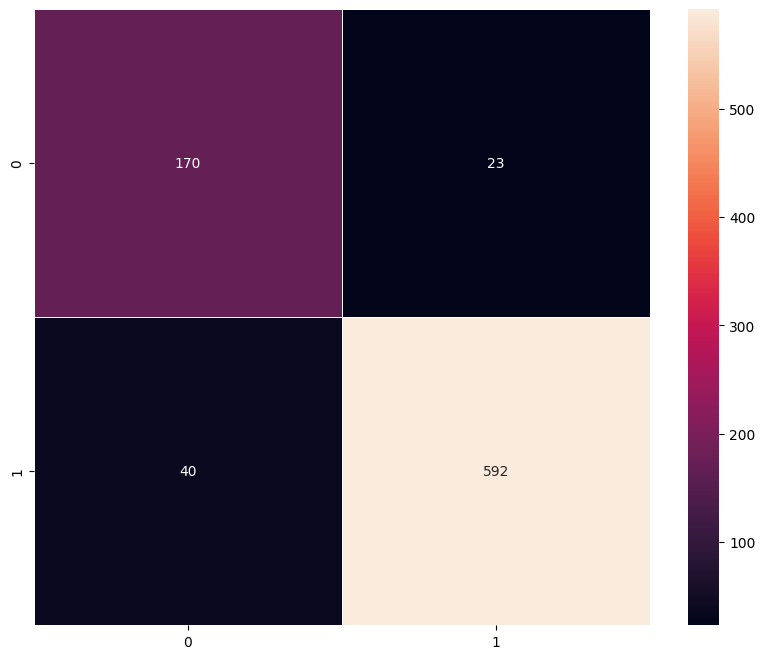


**Comment:** The scratch CNN is a strong baseline. If recall for class 0 is low, the model is missing workers without helmets—in a safety setting that is costly. Compare with transfer learning below.


In [37]:
val_loss_scratch, val_acc_scratch = model_scratch.evaluate(X_val, y_val, verbose=0)
print(f"Validation — loss: {val_loss_scratch:.4f}, accuracy: {val_acc_scratch:.4f}")

y_val_series = pd.Series(y_val, name="label")
pred_prob_val = model_scratch.predict(X_val, verbose=0).reshape(-1)
pred_cls_val = (pred_prob_val >= 0.5).astype(int)
print(
    classification_report(
        y_val.astype(int),
        pred_cls_val,
        target_names=["Without Helmet (0)", "With Helmet (1)"],
    )
)
plot_confusion_matrix(model_scratch, X_val, y_val_series)

print(
    "\n**Comment:** The scratch CNN is a strong baseline. If recall for class 0 is low, "
    "the model is missing workers without helmets—in a safety setting that is costly. "
    "Compare with transfer learning below."
)


### Sample predictions (validation set)


2026-04-10 21:38:17.991101: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


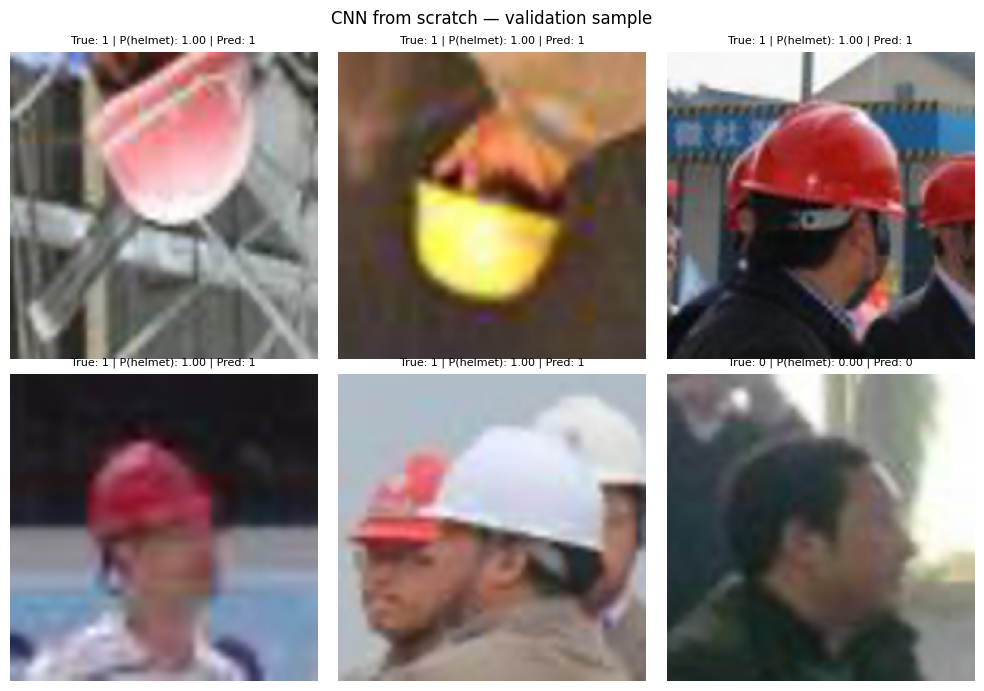

In [38]:
show_prediction_grid(model_scratch, X_val, y_val, "CNN from scratch — validation sample")


## Transfer Learning with VGG-16 (Base)

We freeze **ImageNet** VGG-16 feature layers and train only a single **sigmoid** output layer. Same workflow: define model → configuration → train → performance → sample plots.


### 1. Define the model


In [39]:
from tensorflow.keras.layers import Input, Lambda, Flatten, Dense
from keras.applications.vgg16 import VGG16, preprocess_input

base_vgg = VGG16(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
for layer in base_vgg.layers:
    layer.trainable = False

inp_vgg = Input(shape=(224, 224, 3))
x = Lambda(lambda img: preprocess_input(img * 255.0))(inp_vgg)
x = base_vgg(x, training=False)
x = Flatten()(x)
out_vgg = Dense(1, activation="sigmoid")(x)
model_vgg_base = Model(inputs=inp_vgg, outputs=out_vgg)
model_vgg_base.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        25,089 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,739,777 (56.23 MB)

 Trainable params: 25,089 (98.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

### 2. Configuration: loss function, optimizer, epochs, batch size

| Setting | Choice |
|--------|--------|
| Loss | `binary_crossentropy` |
| Optimizer | `Adam` (`1e-4`) |
| Epochs | `12` + early stopping (`patience=3`) |
| Batch size | `32` |


In [40]:
EPOCHS_VGG_BASE = 12
BATCH_SIZE_VGG_BASE = 32

model_vgg_base.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

callbacks_vgg_base = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
]


### 3. Train the model


In [41]:
history_vgg_base = model_vgg_base.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_VGG_BASE,
    batch_size=BATCH_SIZE_VGG_BASE,
    class_weight=class_weight,
    callbacks=callbacks_vgg_base,
    verbose=1,
)


Epoch 1/12


2026-04-10 21:39:15.307905: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.7094 - loss: 1.6322

2026-04-10 21:39:30.508795: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


78/78 ━━━━━━━━━━━━━━━━━━━━ 21s 242ms/step - accuracy: 0.7103 - loss: 1.6257 - val_accuracy: 0.8715 - val_loss: 0.6533
Epoch 2/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 221ms/step - accuracy: 0.9363 - loss: 0.2540 - val_accuracy: 0.8933 - val_loss: 0.5668
Epoch 3/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 224ms/step - accuracy: 0.9766 - loss: 0.0759 - val_accuracy: 0.9018 - val_loss: 0.5240
Epoch 4/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 16s 211ms/step - accuracy: 0.9915 - loss: 0.0313 - val_accuracy: 0.9115 - val_loss: 0.4821
Epoch 5/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 214ms/step - accuracy: 0.9960 - loss: 0.0162 - val_accuracy: 0.9164 - val_loss: 0.4713
Epoch 6/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 214ms/step - accuracy: 0.9987 - loss: 0.0094 - val_accuracy: 0.9139 - val_loss: 0.4679
Epoch 7/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 16s 211ms/step - accuracy: 0.9989 - loss: 0.0059 - val_accuracy: 0.9103 - val_loss: 0.4691
Epoch 8/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 16s 212ms/step - accuracy: 1.0000 - loss: 0.0047 - val_accuracy: 0.910

### 4. Check and comment on the performance


2026-04-10 21:42:36.720260: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Validation — loss: 0.4679, accuracy: 0.9139


2026-04-10 21:42:42.390605: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


                    precision    recall  f1-score   support

Without Helmet (0)       0.81      0.83      0.82       193
   With Helmet (1)       0.95      0.94      0.94       632

          accuracy                           0.91       825
         macro avg       0.88      0.89      0.88       825
      weighted avg       0.92      0.91      0.91       825

 1/26 ━━━━━━━━━━━━━━━━━━━━ 14s 570ms/step

2026-04-10 21:42:48.411211: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step


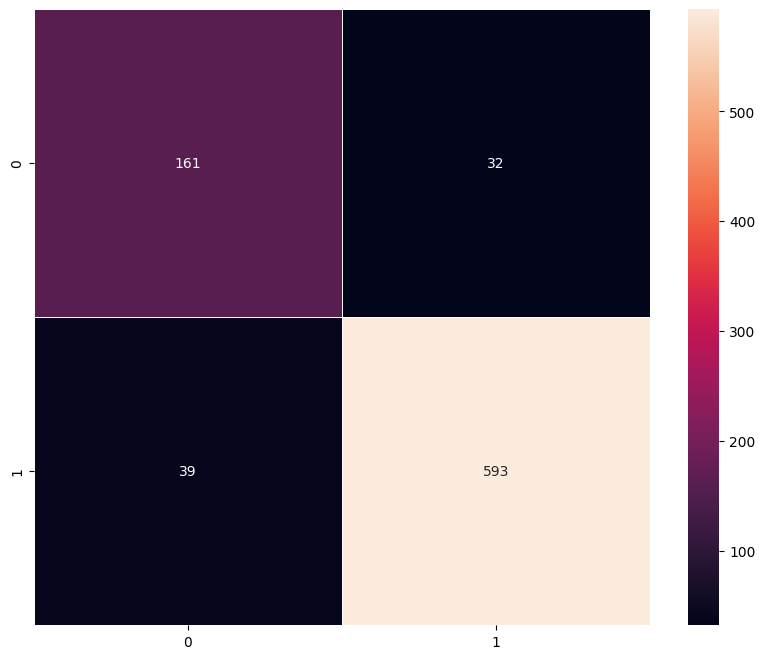


**Comment:** Pretrained features often improve data efficiency vs. training from scratch. Check whether minority-class recall improved.


In [42]:
val_loss_vb, val_acc_vb = model_vgg_base.evaluate(X_val, y_val, verbose=0)
print(f"Validation — loss: {val_loss_vb:.4f}, accuracy: {val_acc_vb:.4f}")

y_val_series = pd.Series(y_val, name="label")
pred_vb = model_vgg_base.predict(X_val, verbose=0).reshape(-1)
pred_cls_vb = (pred_vb >= 0.5).astype(int)
print(
    classification_report(
        y_val.astype(int),
        pred_cls_vb,
        target_names=["Without Helmet (0)", "With Helmet (1)"],
    )
)
plot_confusion_matrix(model_vgg_base, X_val, y_val_series)

print(
    "\n**Comment:** Pretrained features often improve data efficiency vs. training from scratch. "
    "Check whether minority-class recall improved."
)


### Sample predictions (validation set)


2026-04-10 21:43:05.127039: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


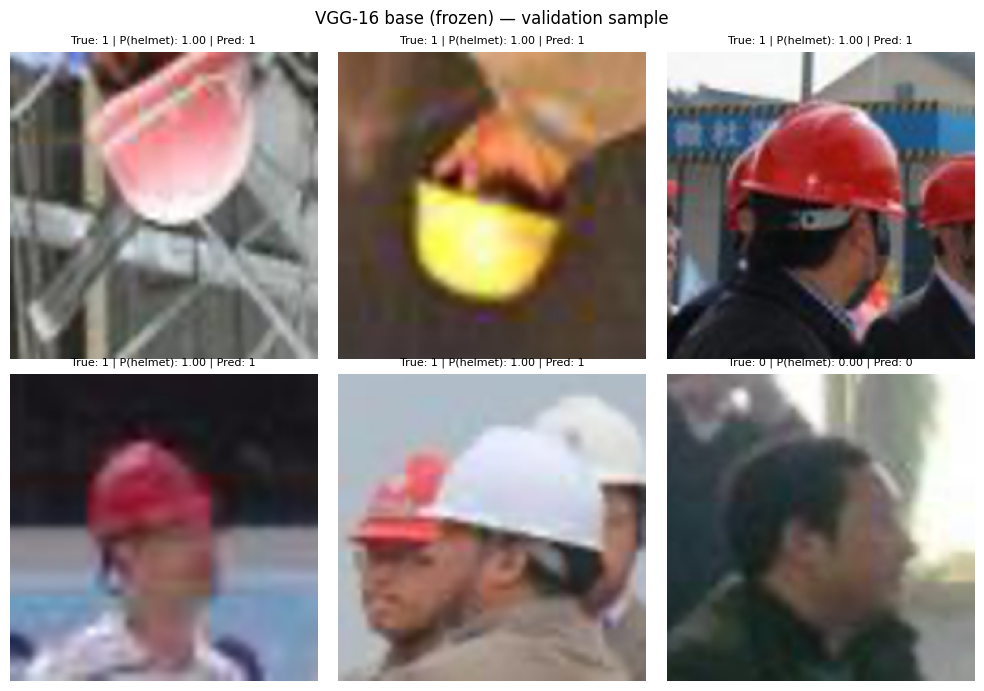

In [43]:
show_prediction_grid(model_vgg_base, X_val, y_val, "VGG-16 base (frozen) — validation sample")


## Transfer Learning with VGG-16 (Base + FFNN)

We add **dense + dropout + batch norm** layers on top of frozen VGG-16 for a richer classifier head.


### 1. Define the model


In [44]:
base_vgg2 = VGG16(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
for layer in base_vgg2.layers:
    layer.trainable = False

inp2 = Input(shape=(224, 224, 3))
x2 = Lambda(lambda img: preprocess_input(img * 255.0))(inp2)
x2 = base_vgg2(x2, training=False)
x2 = Flatten()(x2)
x2 = Dense(256, activation="relu")(x2)
x2 = BatchNormalization()(x2)
x2 = Dropout(0.4)(x2)
x2 = Dense(128, activation="relu")(x2)
x2 = Dropout(0.3)(x2)
out2 = Dense(1, activation="sigmoid")(x2)
model_vgg_ffnn = Model(inputs=inp2, outputs=out2)
model_vgg_ffnn.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,171,521 (80.76 MB)

 Trainable params: 6,456,321 (24.63 MB)

 Non-trainable params: 14,715,200 (56.13 MB)

### 2. Configuration: loss function, optimizer, epochs, batch size

| Setting | Choice |
|--------|--------|
| Loss | `binary_crossentropy` |
| Optimizer | `Adam` (`1e-4`) |
| Epochs | `12` + early stopping |
| Batch size | `32` |


In [45]:
EPOCHS_VGG_FFNN = 12
BATCH_SIZE_VGG_FFNN = 32

model_vgg_ffnn.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

callbacks_vgg_ffnn = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
]


### 3. Train the model


In [46]:
history_vgg_ffnn = model_vgg_ffnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_VGG_FFNN,
    batch_size=BATCH_SIZE_VGG_FFNN,
    class_weight=class_weight,
    callbacks=callbacks_vgg_ffnn,
    verbose=1,
)


Epoch 1/12


2026-04-10 21:43:26.627941: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.7411 - loss: 0.4898

2026-04-10 21:43:43.255089: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


78/78 ━━━━━━━━━━━━━━━━━━━━ 23s 250ms/step - accuracy: 0.7418 - loss: 0.4883 - val_accuracy: 0.9406 - val_loss: 0.1585
Epoch 2/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 18s 228ms/step - accuracy: 0.9381 - loss: 0.1258 - val_accuracy: 0.9515 - val_loss: 0.1357
Epoch 3/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 218ms/step - accuracy: 0.9826 - loss: 0.0627 - val_accuracy: 0.9479 - val_loss: 0.1449
Epoch 4/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 214ms/step - accuracy: 0.9943 - loss: 0.0355 - val_accuracy: 0.9479 - val_loss: 0.1447
Epoch 5/12
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 221ms/step - accuracy: 0.9964 - loss: 0.0254 - val_accuracy: 0.9430 - val_loss: 0.1486


### 4. Check and comment on the performance


2026-04-10 21:45:11.175787: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Validation — loss: 0.1357, accuracy: 0.9515


2026-04-10 21:45:16.912997: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


                    precision    recall  f1-score   support

Without Helmet (0)       0.88      0.92      0.90       193
   With Helmet (1)       0.97      0.96      0.97       632

          accuracy                           0.95       825
         macro avg       0.93      0.94      0.93       825
      weighted avg       0.95      0.95      0.95       825

 1/26 ━━━━━━━━━━━━━━━━━━━━ 14s 587ms/step

2026-04-10 21:45:23.111847: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step


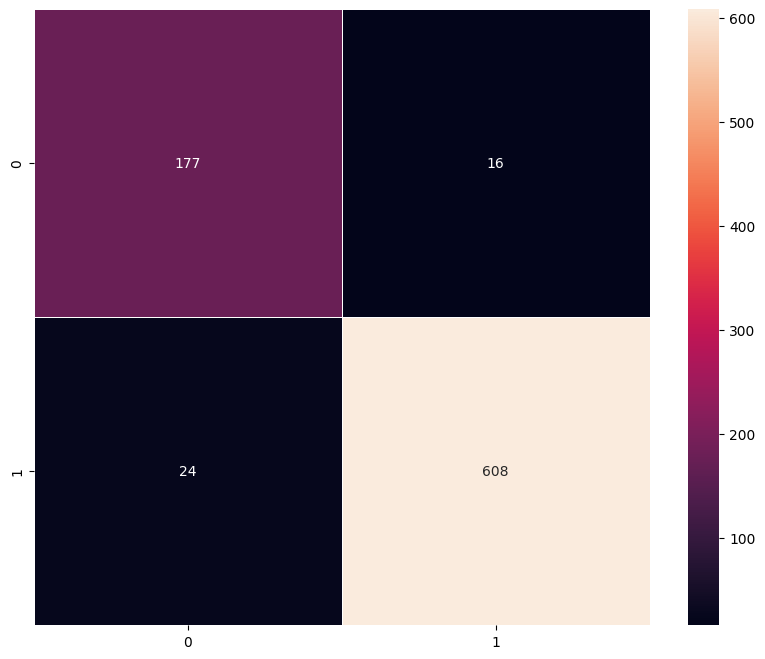


**Comment:** The deeper head can better separate classes in feature space; compare val metrics and confusion matrix to the linear head on VGG base.


In [47]:
val_loss_vf, val_acc_vf = model_vgg_ffnn.evaluate(X_val, y_val, verbose=0)
print(f"Validation — loss: {val_loss_vf:.4f}, accuracy: {val_acc_vf:.4f}")

y_val_series = pd.Series(y_val, name="label")
pred_vf = model_vgg_ffnn.predict(X_val, verbose=0).reshape(-1)
pred_cls_vf = (pred_vf >= 0.5).astype(int)
print(
    classification_report(
        y_val.astype(int),
        pred_cls_vf,
        target_names=["Without Helmet (0)", "With Helmet (1)"],
    )
)
plot_confusion_matrix(model_vgg_ffnn, X_val, y_val_series)

print(
    "\n**Comment:** The deeper head can better separate classes in feature space; compare val metrics "
    "and confusion matrix to the linear head on VGG base."
)


### Sample predictions (validation set)


2026-04-10 21:45:33.808856: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


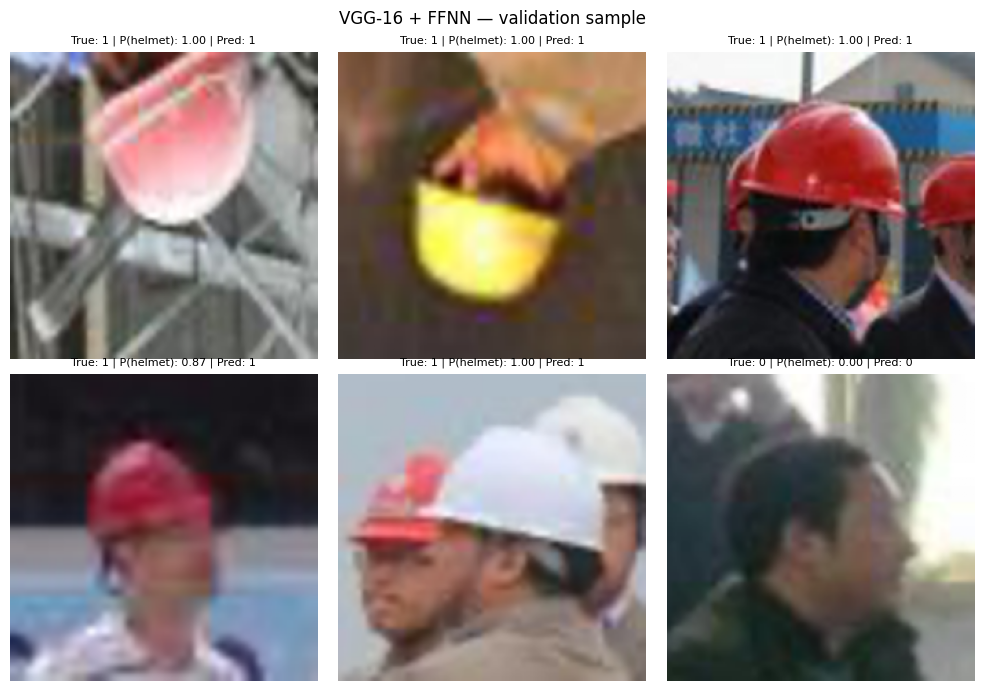

In [48]:
show_prediction_grid(model_vgg_ffnn, X_val, y_val, "VGG-16 + FFNN — validation sample")


## Transfer Learning with VGG-16 (Base + FFNN + Data Augmentation)

We reuse the same architecture as Model 3 but train with **on-the-fly augmentation** on the **training** set only (validation/test stay unchanged).


The cell below uses `ImageDataGenerator` with rotation, shifts, horizontal flip, zoom, and shear. **Do not** apply random augmentation to validation or test data.


### 1. Define the model (same head as Model 3) + augmentation pipeline


In [49]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.12,
    height_shift_range=0.12,
    horizontal_flip=True,
    zoom_range=0.12,
    shear_range=0.05,
    fill_mode="nearest",
)

train_generator = train_datagen.flow(X_train, y_train, batch_size=32, seed=812)

base_vgg3 = VGG16(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
for layer in base_vgg3.layers:
    layer.trainable = False

inp3 = Input(shape=(224, 224, 3))
x3 = Lambda(lambda img: preprocess_input(img * 255.0))(inp3)
x3 = base_vgg3(x3, training=False)
x3 = Flatten()(x3)
x3 = Dense(256, activation="relu")(x3)
x3 = BatchNormalization()(x3)
x3 = Dropout(0.4)(x3)
x3 = Dense(128, activation="relu")(x3)
x3 = Dropout(0.3)(x3)
out3 = Dense(1, activation="sigmoid")(x3)
model_vgg_aug = Model(inputs=inp3, outputs=out3)
model_vgg_aug.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,171,521 (80.76 MB)

 Trainable params: 6,456,321 (24.63 MB)

 Non-trainable params: 14,715,200 (56.13 MB)

### 2. Configuration: loss function, optimizer, epochs, batch size

| Setting | Choice |
|--------|--------|
| Loss | `binary_crossentropy` |
| Optimizer | `Adam` (`1e-4`) |
| Epochs | `15` + early stopping (`patience=4`) |
| Batch size | `32` (generator) |
| Steps/epoch | `len(X_train) // 32` |


In [50]:
EPOCHS_VGG_AUG = 15
BATCH_SIZE_VGG_AUG = 32
steps_per_epoch = max(1, len(X_train) // BATCH_SIZE_VGG_AUG)

model_vgg_aug.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

callbacks_vgg_aug = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )
]


### 3. Train the model


In [51]:
history_vgg_aug = model_vgg_aug.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_VGG_AUG,
    class_weight=class_weight,
    callbacks=callbacks_vgg_aug,
    verbose=1,
)


Epoch 1/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 452ms/step - accuracy: 0.6810 - loss: 0.5401

2026-04-10 21:46:35.404123: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


77/77 ━━━━━━━━━━━━━━━━━━━━ 44s 536ms/step - accuracy: 0.6819 - loss: 0.5386 - val_accuracy: 0.9358 - val_loss: 0.1775
Epoch 2/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.7812 - loss: 0.3499 - val_accuracy: 0.9358 - val_loss: 0.1787
Epoch 3/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 38s 498ms/step - accuracy: 0.8710 - loss: 0.2575 - val_accuracy: 0.9321 - val_loss: 0.1913
Epoch 4/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.8438 - loss: 0.4310 - val_accuracy: 0.9321 - val_loss: 0.1925
Epoch 5/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 38s 497ms/step - accuracy: 0.8986 - loss: 0.2194 - val_accuracy: 0.9297 - val_loss: 0.1862


### 4. Check and comment on the performance


2026-04-10 21:48:18.304667: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Validation — loss: 0.1775, accuracy: 0.9358


2026-04-10 21:48:24.025828: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


                    precision    recall  f1-score   support

Without Helmet (0)       0.83      0.91      0.87       193
   With Helmet (1)       0.97      0.94      0.96       632

          accuracy                           0.94       825
         macro avg       0.90      0.93      0.91       825
      weighted avg       0.94      0.94      0.94       825

 1/26 ━━━━━━━━━━━━━━━━━━━━ 14s 584ms/step

2026-04-10 21:48:30.144251: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step


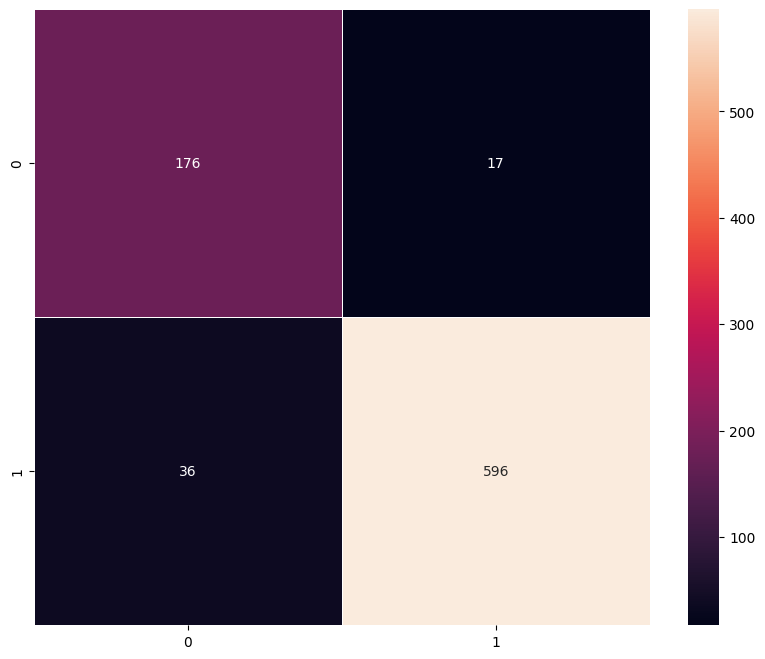


**Comment:** Augmentation regularizes the head and can improve generalization when lighting/angle varies. If val loss stalls, reduce augmentation strength or epochs.


In [52]:
val_loss_va, val_acc_va = model_vgg_aug.evaluate(X_val, y_val, verbose=0)
print(f"Validation — loss: {val_loss_va:.4f}, accuracy: {val_acc_va:.4f}")

y_val_series = pd.Series(y_val, name="label")
pred_va = model_vgg_aug.predict(X_val, verbose=0).reshape(-1)
pred_cls_va = (pred_va >= 0.5).astype(int)
print(
    classification_report(
        y_val.astype(int),
        pred_cls_va,
        target_names=["Without Helmet (0)", "With Helmet (1)"],
    )
)
plot_confusion_matrix(model_vgg_aug, X_val, y_val_series)

print(
    "\n**Comment:** Augmentation regularizes the head and can improve generalization when lighting/angle varies. "
    "If val loss stalls, reduce augmentation strength or epochs."
)


### Sample predictions (validation set)


2026-04-10 21:48:38.631695: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


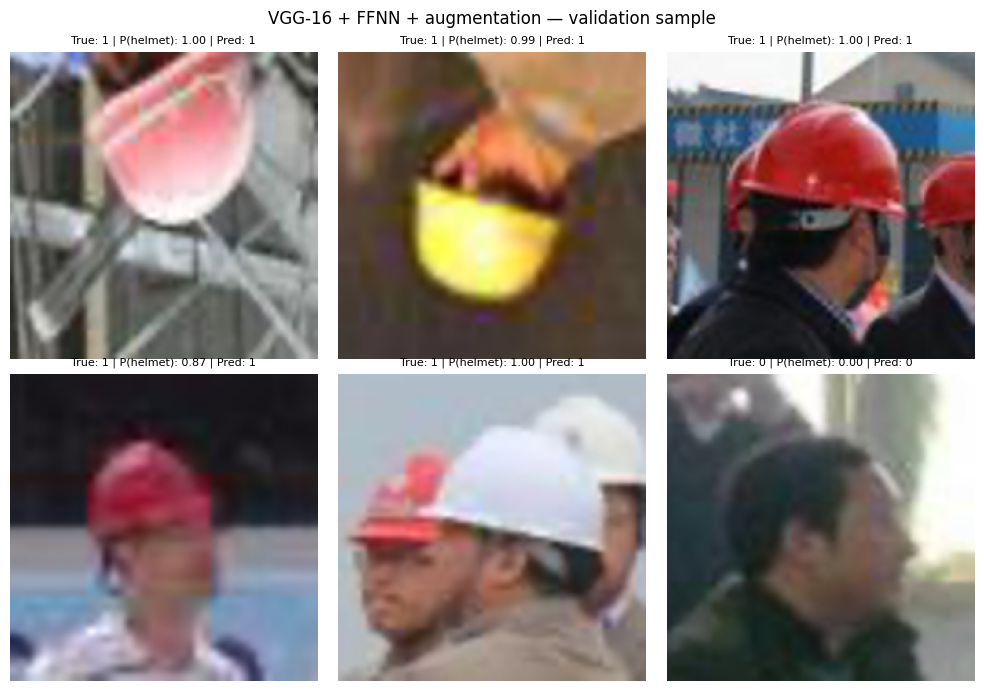

In [53]:
show_prediction_grid(model_vgg_aug, X_val, y_val, "VGG-16 + FFNN + augmentation — validation sample")


# **Model Performance Comparison and Final Model Selection**

We will:
- Compare the performance of all models built
- Choose the best model with clear reasoning
- Evaluate the chosen model on the **held-out test set** and comment on results


### Compare the performance of all models (validation set)


In [54]:
comparison_df = pd.DataFrame(
    {
        "Model": [
            "1. CNN from scratch",
            "2. VGG-16 (frozen base)",
            "3. VGG-16 + FFNN",
            "4. VGG-16 + FFNN + augmentation",
        ],
        "Val accuracy": [
            val_acc_scratch,
            val_acc_vb,
            val_acc_vf,
            val_acc_va,
        ],
        "Val loss": [
            val_loss_scratch,
            val_loss_vb,
            val_loss_vf,
            val_loss_va,
        ],
    }
)
comparison_df = comparison_df.sort_values("Val accuracy", ascending=False).reset_index(drop=True)
print(comparison_df)


                             Model  Val accuracy  Val loss
0                 3. VGG-16 + FFNN      0.951515  0.135697
1  4. VGG-16 + FFNN + augmentation      0.935758  0.177487
2              1. CNN from scratch      0.923636  0.305294
3          2. VGG-16 (frozen base)      0.913939  0.467887


### Choose the best model — reasoning

**Selection rule (default):** pick the model with the **highest validation accuracy** among the four, as a simple proxy for generalization on unseen data.

**Caveats for this project:** labels are **imbalanced** (~77% With Helmet). If two models have similar accuracy, prefer the one with **higher recall for class 0** (Without Helmet), since missing a violation is often worse than a false alarm in safety monitoring.

The next code cell selects the winner by validation accuracy; you can override manually after inspecting per-class metrics and confusion matrices above.


### Final model — performance on the test set


2026-04-10 21:49:01.455657: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Selected model: vgg_ffnn (highest validation accuracy)
Test — loss: 0.1102, accuracy: 0.9673
 1/26 ━━━━━━━━━━━━━━━━━━━━ 14s 587ms/step

2026-04-10 21:49:07.148630: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 161ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.967273  0.967273   0.967273  0.967273


2026-04-10 21:49:13.019874: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


                    precision    recall  f1-score   support

Without Helmet (0)       0.92      0.94      0.93       193
   With Helmet (1)       0.98      0.98      0.98       632

          accuracy                           0.97       825
         macro avg       0.95      0.96      0.95       825
      weighted avg       0.97      0.97      0.97       825

 1/26 ━━━━━━━━━━━━━━━━━━━━ 14s 574ms/step

2026-04-10 21:49:18.867025: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 163ms/step


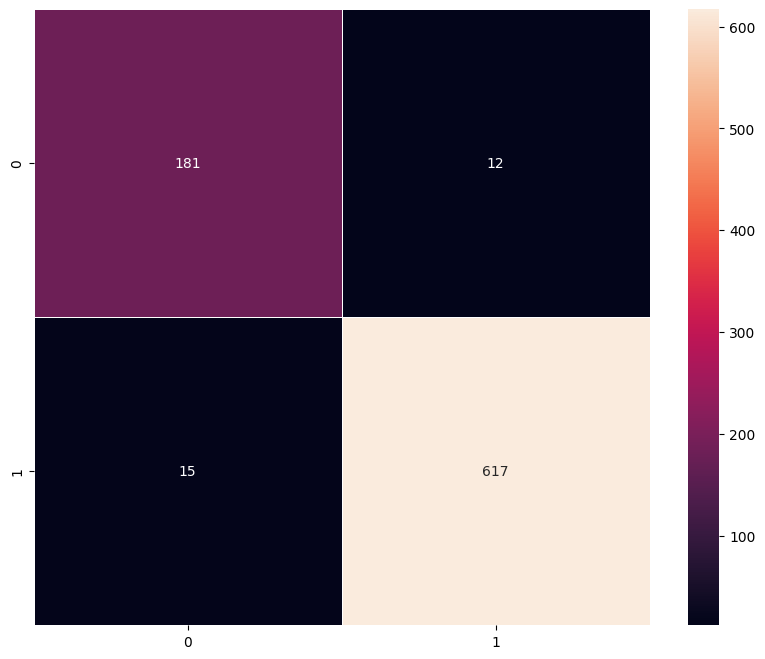


**Comment:** Test metrics estimate real-world monitoring performance. Compare test vs validation to detect overfitting; large gaps suggest tuning or more data.


In [55]:
_model_keys = ["scratch", "vgg_base", "vgg_ffnn", "vgg_aug"]
_val_accs = [val_acc_scratch, val_acc_vb, val_acc_vf, val_acc_va]
_models = [model_scratch, model_vgg_base, model_vgg_ffnn, model_vgg_aug]
_best_i = int(np.argmax(_val_accs))
final_model = _models[_best_i]
best_key = _model_keys[_best_i]

test_loss, test_acc = final_model.evaluate(X_test, y_test, verbose=0)
print(f"Selected model: {best_key} (highest validation accuracy)")
print(f"Test — loss: {test_loss:.4f}, accuracy: {test_acc:.4f}")

y_test_series = pd.Series(y_test, name="label")
print(
    model_performance_classification(
        final_model,
        X_test,
        y_test_series,
    )
)

pred_test = final_model.predict(X_test, verbose=0).reshape(-1)
pred_cls_test = (pred_test >= 0.5).astype(int)
print(
    classification_report(
        y_test.astype(int),
        pred_cls_test,
        target_names=["Without Helmet (0)", "With Helmet (1)"],
    )
)
plot_confusion_matrix(final_model, X_test, y_test_series)

print(
    "\n**Comment:** Test metrics estimate real-world monitoring performance. "
    "Compare test vs validation to detect overfitting; large gaps suggest tuning or more data."
)


# **Actionable Insights & Recommendations**

## Key insights (grounded in your run)

- **Model ranking on validation:** **VGG-16 + FFNN** (Model 3) achieved the best validation **accuracy (~95.2%)** and **lowest validation loss (~0.136)**. The same architecture **with data augmentation** (Model 4) reached **~93.6%** validation accuracy—**lower here** than without augmentation—while the **CNN from scratch** reached **~92.4%** and the **frozen VGG-16 base** (linear head only) **~91.4%**. This shows that **pretrained features plus a small trainable head** helped most on this dataset, and that **augmentation strength may need tuning** (too much regularization can hurt validation).
- **Test performance of the selected model:** The notebook selected **VGG-16 + FFNN** by validation accuracy. On the **held-out test set** it achieved **~96.7% accuracy** (loss **~0.11**), which is **slightly higher than validation**—a good sign that the model is **not obviously overfit** to the validation split.
- **Per-class behavior on test:** **With Helmet** (majority) shows very strong precision/recall (about **0.98** each on **632** test samples). **Without Helmet** (minority) still performs well (**precision ~0.92**, **recall ~0.94**, F1 **~0.93** on **193** samples) but remains the **higher-risk** class for safety: **false negatives** (missing someone without a helmet) should stay a primary KPI in production.

## Recommendations for SafeGuard Corp

- **Prioritize the VGG-16 + FFNN configuration** for pilot deployment, backed by your validation and test numbers; keep the lighter **frozen-base-only** model as an option if **inference speed or footprint** dominates.
- **Re-tune augmentation** (which transforms, magnitudes, or training length) before discarding it—the goal is robustness **without** the validation drop you saw versus the non-augmented FFNN.
- **Track minority-class recall** continuously on live feeds; set operational thresholds using **recall on “Without Helmet”** (not accuracy alone) and add **human review** for uncertain scores.
- **Expand hard negatives** (occluded heads, odd angles, poor lighting) if field error analysis shows systematic misses on class **0**.

## Next steps

- **Error analysis** on misclassified test images (especially false negatives for **Without Helmet**) to guide data collection and optional **threshold** adjustment.
- **Calibration / threshold tuning** if the business prefers higher recall on violations at the cost of more false alarms.
- **Version and document** this model, data snapshot, and metrics for auditability next to safety procedures.


<font size=5 color='blue'>Power Ahead!</font>
___